In [7]:

import matplotlib.gridspec as gridspec
import os
import sys

import scipy.stats
import umap
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder
from BWM.models.isometric_autoencoder import get_density_proxy
active_lambda = 0.1 # Default value if not imported
sys.path.append(os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [8]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    #row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    #X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_transposed


directory_path='../Data2'
eids = [d for d in os.listdir(directory_path) if os.path.isdir(os.path.join(directory_path, d))]
# result = get_region_response_matrix(
#                 region=['CP'],
#                 eids=eids,
#                 directory_path=directory_path,
#                 event="stimOn_times",
#                 conditions=['choice'],
#                 n_pseudo=25,
#                 threshold=5,
#                 std_above=50,
#                 std_below=50,
#                 filter_significant=False,
#                 n_steps=100,
#                 step=0.01,
#                 sigma=1,
#                 mapping='Beryl'
#             )
# pseudo_response_tensor =result[0]
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
#pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]



In [9]:
def trial_variability(x):

    z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))
    return (
        np.mean(np.std(z, axis=0),axis=(0,1)))

variability = trial_variability(pseudo_response_tensor)
pseudo_response_tensor=pseudo_response_tensor[:,:,:,variability<.7]

X_input = iso_ae_preprocessing(pseudo_response_tensor)


In [10]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    speed= np.mean(np.abs(np.diff(z,axis=1)),axis=(0,1))

    return speed

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

In [5]:
# Plot densmap projection of EID responses
# #Figure 1
# fig = plt.figure(figsize=(4, 2))
# gs = gridspec.GridSpec(1, 2)
# ax1 = plt.subplot(gs[0,0])
# ax2 = plt.subplot(gs[0,1])
#
# # First row
# #from sklearn.manifold import Isomap
# z_neurons = umap.UMAP(densmap = True, dens_lambda=5, n_neighbors=500).fit_transform(X_input,randoma_seed=42)
# sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=1,legend=False,alpha =.5)
# sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = msd_data,ax=ax2,palette='turbo',s=1,alpha = .5,legend=False)


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

SklearnIsometricAutoencoder(epochs=1000, hidden_dim=32, lambda_density=10,
                            lambda_iso=0.0)

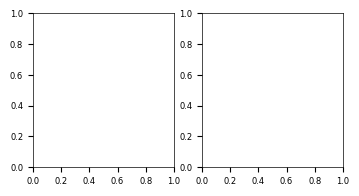

In [19]:
# Plot densmap projection of EID responses
#Figure 1
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])

# First row
#from sklearn.manifold import Isomap
# iso_ae = SklearnIsometricAutoencoder(latent_dim=2,hidden_dim=32,depth =2,lambda_iso=0.0, lambda_density=10,device='cpu',epochs = 1000)

iso_ae.fit(X_input)



<Axes: >

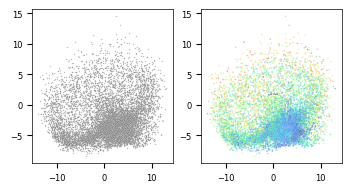

In [18]:
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
z_neurons = iso_ae.transform(X_input)
sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=1,legend=False,alpha =.5)
sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = msd_data,ax=ax2,palette='turbo',s=1,alpha = .5,legend=False)

<Axes: xlabel='None', ylabel='None'>

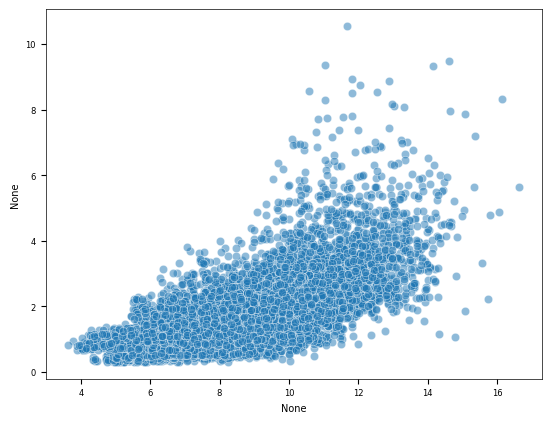

In [14]:
data_density=get_density_proxy(X_input, k=100)
latent_density=get_density_proxy(z_neurons, k=100)
plt.figure()
sns.scatterplot(x=data_density,y=latent_density,alpha=.5)

In [ ]:
import scipy
scipy.stats.pearsonr(x=data_density,y=latent_density)